# Comparativa de detectores - matrículas

En este cuaderno auxiliar se evalúan y comparan los detectores de matrículas. Esto permite justificar la elección del detector utilizado en la segunda parte de la práctica. Se comparan:

- **YOLO26-X** y **RT-DETRv4-L**, entrenados en [`plates_module2/train_plate_detectors.ipynb`](./plates_module2/train_plate_detectors.ipynb), con los pesos de su mejor época (`best`) y de la última (`last`).
- El detector clásico **por contornos**, sin redes neuronales, de [`plates_module2/contours.ipynb`](./plates_module2/contours.ipynb).

## Evaluación

Todos los detectores se evalúan en las mismas condiciones:

- **Datos:** los recortes de vehículos de _test_ (`data/vehicles/test`), que no se han usado para entrenar las redes ni para ajustar el detector por contornos. Se incluyen los recortes sin matrícula, en los que cualquier detección es un falso positivo.
- **Métricas:** mAP@50-95 y mAP@50, además de _precision_, _recall_ y _accuracy_ con confianza ≥ 0.5 e IoU ≥ 0.5.
- **Tiempo:** inferencia completa por recorte (preprocesado, modelo y postprocesado), con _batch_ 1, sin contar la lectura de disco.

## Índice

1. [Preparación](#1-preparación)
    - [1.1 Configuración](#11-configuración)
    - [1.2 Información del equipo](#12-información-del-equipo)
2. [Conjunto de datos](#2-conjunto-de-datos)
3. [Detectores](#3-detectores)
4. [Evaluación de los modelos](#4-evaluación-de-los-modelos)
    - [4.1 Comprobación sobre algunos recortes](#41-comprobación-sobre-algunos-recortes)
    - [4.2 Generación de métricas](#42-generación-de-métricas)
    - [4.3 Resultados](#43-resultados)
5. [TensorBoard](#5-tensorboard)
6. [Conclusiones](#6-conclusiones)

## 1. Preparación

### 1.1 Configuración

El código común a varios cuadernos está en [`common/`](./common): rutas, construcción de RT-DETRv4, detectores de matrículas y métricas de detección:

In [1]:
import json
import random
import shutil
from collections import defaultdict

import cv2
import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch.utils.tensorboard import SummaryWriter

from common.det_metrics import coco_map, get_metrics, timed_inference, to_coco_dets
from common.detectors import ContourPlateDetector, DetrDetector, YoloDetector
from common.paths import PLATES_DATA, PLATES_RUNS
from common.specs import save_system_info

Rutas de los recortes de _test_, de los entrenamientos y de los resultados de la comparativa:

In [2]:
TEST = PLATES_DATA / "test"
TEST_JSON = TEST / "coco.json"
YOLO_RUN = PLATES_RUNS / "yolo26x"
RTDETR_RUN = PLATES_RUNS / "rtdetrv4_l"
RESULTS = PLATES_RUNS / "test"
TENSORBOARD = RESULTS / "tensorboard"

RESULTS.mkdir(parents=True, exist_ok=True)
if not TEST_JSON.exists():
    raise FileNotFoundError(f"No existe {TEST_JSON}: ejecuta antes plates_module2/train_plate_detectors.ipynb")

Parámetros de la comparativa:

- `WARMUP`: recortes de calentamiento, que se procesan antes de empezar a medir el tiempo.
- `TOP_K`: número máximo de detecciones por recorte.
- `SCORE_MIN`: confianza mínima de las detecciones que se usan para calcular el mAP.
- `CONF_PRF` e `IOU_PRF`: umbrales de confianza e IoU para calcular _precision_, _recall_ y _accuracy_.
- `FORCE`: si es `False` y un detector ya se ha medido, se reutilizan sus resultados.

In [3]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WARMUP = 10
TOP_K = 300
SCORE_MIN = 0.001
CONF_PRF = 0.5
IOU_PRF = 0.5
FORCE = False

print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(sin GPU)")

device: cuda NVIDIA GeForce RTX 5080


### 1.2 Información del equipo

Los tiempos dependen del equipo en el que se miden, por lo que se guarda esta información en `system_info.json` (ver funciones en [`common/specs.py`](./common/specs.py)):

In [4]:
PACKAGES = ["torch", "torchvision", "ultralytics", "faster-coco-eval", "opencv-python", "numpy", "pandas", "scipy"]

save_system_info(RESULTS / "system_info.json", PACKAGES)

{'os': 'Windows-10-10.0.26200-SP0',
 'cpu': 'AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD',
 'cpu_cores': 8,
 'ram_gb': 34.0,
 'python': '3.11.18',
 'gpu': 'NVIDIA GeForce RTX 5080',
 'gpu_driver': '610.88',
 'cuda': '13.0',
 'packages': {'torch': '2.14.1+cu130',
  'torchvision': '0.29.1+cu130',
  'ultralytics': '8.4.202',
  'faster-coco-eval': '1.8.0',
  'opencv-python': '4.10.0.84',
  'numpy': '2.3.5',
  'pandas': '3.1.1',
  'scipy': '1.17.1'}}

## 2. Conjunto de datos

Se usan los recortes de _test_ generados en [`build_vehicle_dataset.ipynb`](./plates_module2/build_vehicle_dataset.ipynb), con sus anotaciones en formato COCO (`coco.json`, generado en [`train_plate_detectors.ipynb`](./plates_module2/train_plate_detectors.ipynb)). Todas las matrículas son de la clase `plate` (0):

In [5]:
TEST_DATA = json.load(open(TEST_JSON))
IMAGES = TEST_DATA["images"]
CLASSES = {0: "plate"}

PLATES_OF = defaultdict(list)
for a in TEST_DATA["annotations"]:
    PLATES_OF[a["image_id"]].append(a["bbox"])


def read_image(im):
    return cv2.imread(str(TEST / "images" / im["file_name"]))


print(f"{len(IMAGES)} recortes, {len(TEST_DATA['annotations'])} matrículas, {len(IMAGES) - len(PLATES_OF)} recortes sin matrícula")

1256 recortes, 894 matrículas, 535 recortes sin matrícula


## 3. Detectores

Todos los detectores comparten la interfaz `Detector` ([`common/detectors.py`](./common/detectors.py)): reciben un recorte BGR y devuelven las cajas `[x1, y1, x2, y2]` en píxeles, su confianza y su clase (siempre 0 = `plate`).

- **YOLO26-X:** se ejecuta con Ultralytics, que ya incluye el preprocesado y el postprocesado.
- **RT-DETRv4-L:** se construye con la configuración de su entrenamiento (`config.yml`, con ayuda de [`common/detr.py`](./common/detr.py)) y se evalúa con los pesos de su mejor época (`best_stg1.pth`) y de la última (`last.pth`).
- **Contornos:** devuelve como mucho una _bounding box_ por recorte ([`common/contours.py`](./common/contours.py) y [`common/contour_selection.py`](./common/contour_selection.py)).

Cada detector se crea solo cuando se va a medir, para tener un único modelo en la GPU:

In [6]:
DETECTORS = {
    "yolo26x-best": lambda: YoloDetector("yolo26x-best", YOLO_RUN / "weights" / "best.pt", score_min=SCORE_MIN, top_k=TOP_K),
    "yolo26x-last": lambda: YoloDetector("yolo26x-last", YOLO_RUN / "weights" / "last.pt", score_min=SCORE_MIN, top_k=TOP_K),
    "rtdetrv4l-best": lambda: DetrDetector("rtdetrv4l-best", "rtdetrv4", RTDETR_RUN / "config.yml", RTDETR_RUN / "best_stg1.pth", DEVICE, top_k=TOP_K),
    "rtdetrv4l-last": lambda: DetrDetector("rtdetrv4l-last", "rtdetrv4", RTDETR_RUN / "config.yml", RTDETR_RUN / "last.pth", DEVICE, top_k=TOP_K),
    "contours": lambda: ContourPlateDetector("contours"),
}

## 4. Evaluación de los modelos

### 4.1 Comprobación sobre algunos recortes

Antes de medir, se comparan visualmente las detecciones con confianza ≥ `CONF_PRF` (magenta) de cada detector sobre algunos recortes de _test_ con matrícula (verde):

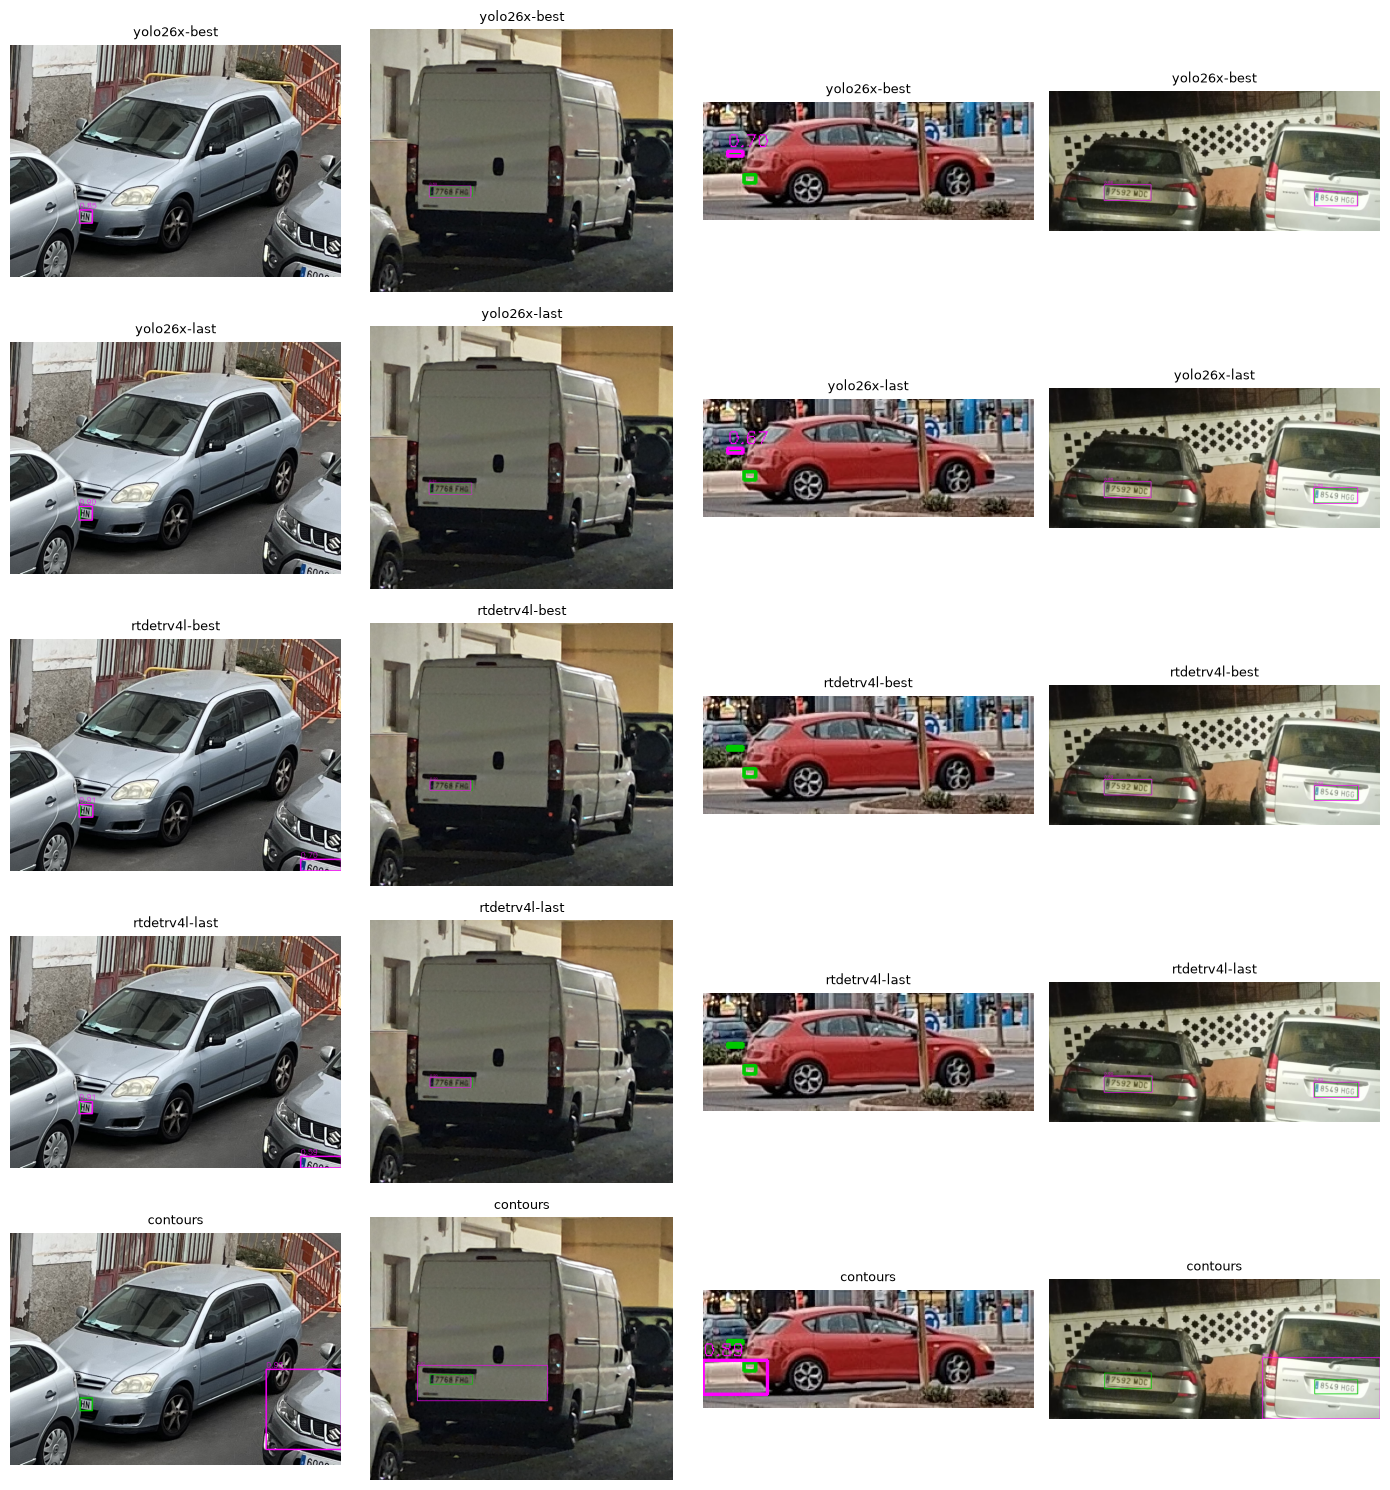

In [7]:
def draw_detections(bgr, boxes, scores, plates, min_score=CONF_PRF):
    out = bgr.copy()
    for x, y, w, h in plates:
        cv2.rectangle(out, (round(x), round(y)), (round(x + w), round(y + h)), (0, 200, 0), 2)
    for (x1, y1, x2, y2), score in zip(boxes, scores):
        if score >= min_score:
            cv2.rectangle(out, (round(x1), round(y1)), (round(x2), round(y2)), (255, 0, 255), 2)
            cv2.putText(out, f"{score:.2f}", (round(x1), max(12, round(y1) - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 255), 1)
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB)


samples = random.Random(0).sample([im for im in IMAGES if PLATES_OF[im["id"]]], 4)
fig, axes = plt.subplots(len(DETECTORS), len(samples), figsize=(3.5 * len(samples), 3 * len(DETECTORS)), squeeze=False)
for row, (name, make) in zip(axes, DETECTORS.items()):
    det = make()
    for ax, im in zip(row, samples):
        bgr = read_image(im)
        boxes, scores, _ = det(bgr)
        ax.imshow(draw_detections(bgr, boxes, scores, PLATES_OF[im["id"]]))
        ax.set_title(name, fontsize=9)
        ax.axis("off")
    det.close()
plt.tight_layout()
plt.show()

### 4.2 Generación de métricas

Para cada detector, primero se procesan algunos recortes sin medir el tiempo (calentamiento). A continuación, se recorren todos los recortes de _test_ midiendo únicamente la ejecución del detector. Las métricas se calculan con [`common/det_metrics.py`](./common/det_metrics.py), igual que en la comparativa de detectores de personas y vehículos.

Las predicciones y la fila de resultados de cada detector se guardan en `runs/plates/test/`, y se reutilizan en las siguientes ejecuciones, a no ser que se indique `FORCE = True`:

In [8]:
def evaluate(name):
    det = DETECTORS[name]()
    try:
        outputs, total_s = timed_inference(det, IMAGES, read_image, WARMUP)
        n_params = det.n_params
    finally:
        det.close()
    dets = [d for im, (boxes, scores, labels) in zip(IMAGES, outputs) for d in to_coco_dets(im["id"], boxes, scores, labels)]
    json.dump(dets, open(RESULTS / f"preds_{name}.json", "w"))

    map_res = coco_map(TEST_JSON, dets, CLASSES)
    prf_res = get_metrics(TEST_JSON, dets, CLASSES, CONF_PRF, IOU_PRF)
    return {"model": name, "params_M": n_params / 1e6, "ms_per_img": 1000 * total_s / len(IMAGES), "fps": len(IMAGES) / total_s,
            "mAP50-95": map_res["mAP50-95"], "mAP50": map_res["mAP50"],
            **{k: prf_res[k] for k in ("precision", "recall", "accuracy", "TP", "FP", "FN")}}


def load_or_measure(name, force=FORCE):
    path = RESULTS / f"metrics_{name}.json"
    if path.exists() and not force:
        return json.load(open(path))
    print(f"Midiendo {name}...", flush=True)
    row = evaluate(name)
    json.dump(row, open(path, "w"), indent=1)
    return row

### 4.3 Resultados

Resultados de todos los detectores, que se juntan en `runs/plates/test/results.csv`:

In [9]:
results = pd.DataFrame([load_or_measure(name) for name in DETECTORS])
results.to_csv(RESULTS / "results.csv", index=False)
results.style.hide(axis="index").format(precision=3)

model,params_M,ms_per_img,fps,mAP50-95,mAP50,precision,recall,accuracy,TP,FP,FN
yolo26x-best,58.811,19.230,52.003,0.789,0.941,0.902,0.919,0.836,822,89,72
yolo26x-last,58.811,16.776,59.610,0.789,0.942,0.905,0.922,0.840,824,87,70
rtdetrv4l-best,30.906,19.838,50.409,0.836,0.969,0.901,0.949,0.859,848,93,46
rtdetrv4l-last,30.906,19.351,51.677,0.836,0.968,0.914,0.943,0.866,843,79,51
contours,0.000,28.248,35.400,0.059,0.112,0.210,0.281,0.136,251,947,643


## 5. TensorBoard

En la pestaña HPARAMS de TensorBoard (`runs/plates/test/tensorboard`) se muestra una tabla con los resultados de todos los detectores:

In [10]:
def log_hparams(row):
    hparams = {"model": row["model"], "params_M": round(row["params_M"], 1)}
    metrics = {f"test/{k}": row[k] for k in ("mAP50-95", "mAP50", "precision", "recall", "accuracy", "ms_per_img")}
    with SummaryWriter(str(TENSORBOARD)) as w:
        w.add_hparams(hparams, metrics, run_name=row["model"])


shutil.rmtree(TENSORBOARD, ignore_errors=True)
for row in results.to_dict("records"):
    log_hparams(row)

## 6. Conclusiones

RT-DETRv4-L es el mejor detector de matrículas, y es el que se utiliza en la práctica:

- **Detección:** con el mejor modelo (`best`), RT-DETRv4-L obtiene un mAP@50-95 de 0.836 y un mAP@50 de 0.969 en _test_, frente a 0.789 y 0.941 de YOLO26-X.
- **Exhaustividad:** RT-DETRv4-L encuentra el 94.9 % de las matrículas (_recall_), frente al 91.9 % de YOLO26-X: de las 894 matrículas de _test_, no detecta 46, frente a 72.
- **Falsos positivos:** ambos modelos tienen una precisión similar (0.90). El último modelo de RT-DETRv4-L (`last`) da menos falsos positivos (79 frente a 93) con el mismo mAP, a cambio de perder alguna matrícula más.
- **Tamaño y tiempo:** RT-DETRv4-L tiene la mitad de parámetros (31 M frente a 59 M), con un tiempo por recorte similar (entre 17 y 20 ms por imagen).
- **Contornos:** el detector clásico queda muy por debajo de los modelos de aprendizaje profundo (mAP@50 de 0.112) y solo encuentra el 28.1 % de las matrículas. Además, sin GPU tarda unos 28 ms por recorte. Esto demuestra las facilidades que otorga el uso de modelos de _Deep Learning_.